# Experiment 1 - Iris Dataset Visualization

## Objective

Load the classic **Iris** flower dataset, inspect and summarise it, and build a
complete set of publication-quality visualizations (bar charts, grouped bars,
scatter plots, box plots, a correlation heatmap and a pair plot). The
experiment demonstrates how the four measurement features separate the three
Iris species and which features are the most discriminative.

## Dataset

| Property | Value |
|---|---|
| Name | Iris flower dataset (UCI ML Repository, via Kaggle) |
| Records | 150 (50 per species) |
| Features | `SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`, `Species` |
| Local file | `Iris.csv` (ships with this folder) |
| License | CC0 / public-domain style UCI dataset - see the repository README |

## Methodology

1. Load the CSV (works locally, in Google Colab and on Kaggle).
2. Inspect shape, dtypes, missing values, duplicates and class balance.
3. Compute descriptive statistics overall and per species.
4. Produce seven visualizations and save each one as a PNG.
5. Interpret the results.

## How to run

* **Local:** `jupyter notebook Iris_Visualization_Colab.ipynb` from `experiment-1/`.
* **Google Colab / Kaggle:** upload this notebook together with `Iris.csv`
  (Kaggle: attach the folder as a dataset and point `IRIS_CSV` at it).
  Figures are written to `outputs/` locally and to `/kaggle/working/outputs/` on Kaggle.


## 2. Import Libraries

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')

# Set style for professional-looking plots
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Iris-inspired color palette
IRIS_COLORS = {'Iris-setosa': '#2196F3', 'Iris-versicolor': '#4CAF50', 'Iris-virginica': '#FF9800'}

# --- where the saved figures go -------------------------------------------
#   Kaggle      -> /kaggle/working/outputs
#   Google Colab-> /content/outputs
#   local       -> ./outputs
if Path('/kaggle/working').exists():
    OUT_DIR = Path('/kaggle/working/outputs')
elif os.environ.get('COLAB_RELEASE_TAG') or Path('/content').exists():
    OUT_DIR = Path('/content/outputs')
else:
    OUT_DIR = Path('outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    """Save the current figure next to the notebook / under /kaggle/working."""
    path = OUT_DIR / name
    plt.savefig(path, dpi=150, bbox_inches='tight')
    return path


print('Libraries imported successfully!')
print('Figures will be saved to:', OUT_DIR.resolve())

Libraries imported successfully!
Figures will be saved to: D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-1\outputs


## 3. Load Dataset

In [2]:
def find_iris_csv():
    """Locate Iris.csv locally, in Google Colab or on Kaggle."""
    env = os.environ.get("IRIS_CSV")
    if env and Path(env).exists():
        return Path(env)

    here = Path.cwd()
    candidates = [
        here / "Iris.csv",
        here / "data" / "Iris.csv",
        here.parent / "data" / "Iris.csv",
        here / "experiment-1" / "Iris.csv",
    ]

    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        candidates.extend(sorted(kaggle_input.glob("**/Iris.csv")))

    for c in candidates:
        if c.exists():
            return c

    # Google Colab: ask the user for the file
    try:
        from google.colab import files  # type: ignore
        print("Iris.csv not found - please upload it.")
        uploaded = files.upload()
        return Path(next(iter(uploaded)))
    except Exception:
        pass

    raise FileNotFoundError(
        "Iris.csv not found. Place it next to this notebook "
        "(experiment-1/Iris.csv), set IRIS_CSV=/path/to/Iris.csv, or attach "
        "it as a Kaggle dataset."
    )


CSV_PATH = find_iris_csv()
df = pd.read_csv(CSV_PATH)
print(f"Loaded: {CSV_PATH}")
print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Loaded: D:\Opean Ai\Data-Visualization-Lab-Experiments\experiment-1\data\Iris.csv
Dataset loaded: 150 rows, 6 columns


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 4. Data Inspection

In [3]:
print(f'Shape: {df.shape}')
print(f'\nColumns: {list(df.columns)}')
print(f'\nData Types:\n{df.dtypes}')

Shape: (150, 6)

Columns: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Data Types:
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object


In [4]:
print(f'Missing Values:\n{df.isnull().sum()}')
print(f'\nDuplicate Rows: {df.duplicated().sum()}')
print(f'\nUnique Species: {df["Species"].unique()}')
print(f'\nSpecies Distribution:\n{df["Species"].value_counts()}')

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate Rows: 0

Unique Species: <StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

Species Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## 5. Data Cleaning

The dataset is clean with no missing values or duplicates. No cleaning required.

## 6. Descriptive Statistics

In [5]:
numeric_cols = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
df[numeric_cols].describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
print('Mean by Species:')
print(df.groupby('Species')[numeric_cols].mean().round(3))
print('\nStd by Species:')
print(df.groupby('Species')[numeric_cols].std().round(3))

Mean by Species:
                 SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
Species                                                                  
Iris-setosa              5.006         3.418          1.464         0.244
Iris-versicolor          5.936         2.770          4.260         1.326
Iris-virginica           6.588         2.974          5.552         2.026

Std by Species:
                 SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
Species                                                                  
Iris-setosa              0.352         0.381          0.174         0.107
Iris-versicolor          0.516         0.314          0.470         0.198
Iris-virginica           0.636         0.322          0.552         0.275


## 7. Species Distribution

Bar chart showing the count of flowers per species.

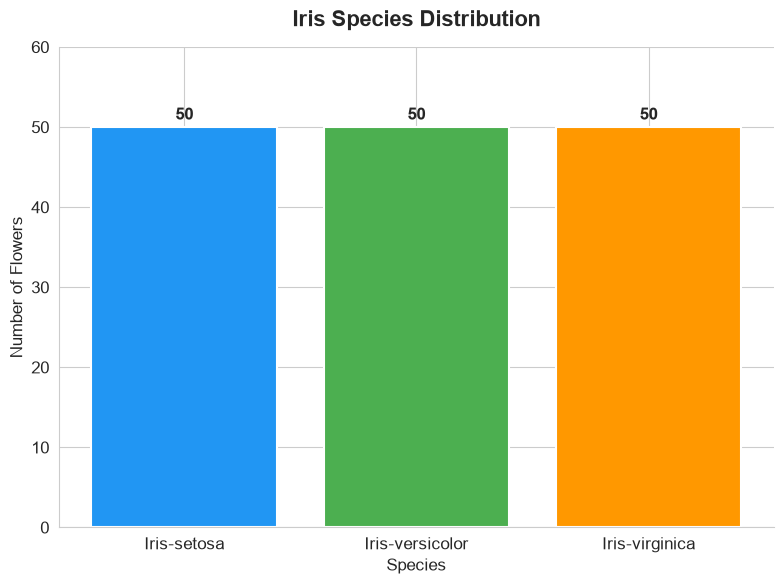

saved outputs\vis1_species_distribution.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
species_counts = df['Species'].value_counts()
bars = ax.bar(species_counts.index, species_counts.values,
              color=[IRIS_COLORS[s] for s in species_counts.index],
              edgecolor='white', linewidth=1.5)
for bar, count in zip(bars, species_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.5,
            str(count), ha='center', va='bottom', fontweight='bold', fontsize=12)
ax.set_title('Iris Species Distribution', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Species', fontsize=12)
ax.set_ylabel('Number of Flowers', fontsize=12)
ax.set_ylim(0, 60)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
_fig = save_figure('vis1_species_distribution.png')
plt.show()
print('saved', _fig)

## 8. Average Measurements by Species

Grouped bar chart comparing the four measurements across species.

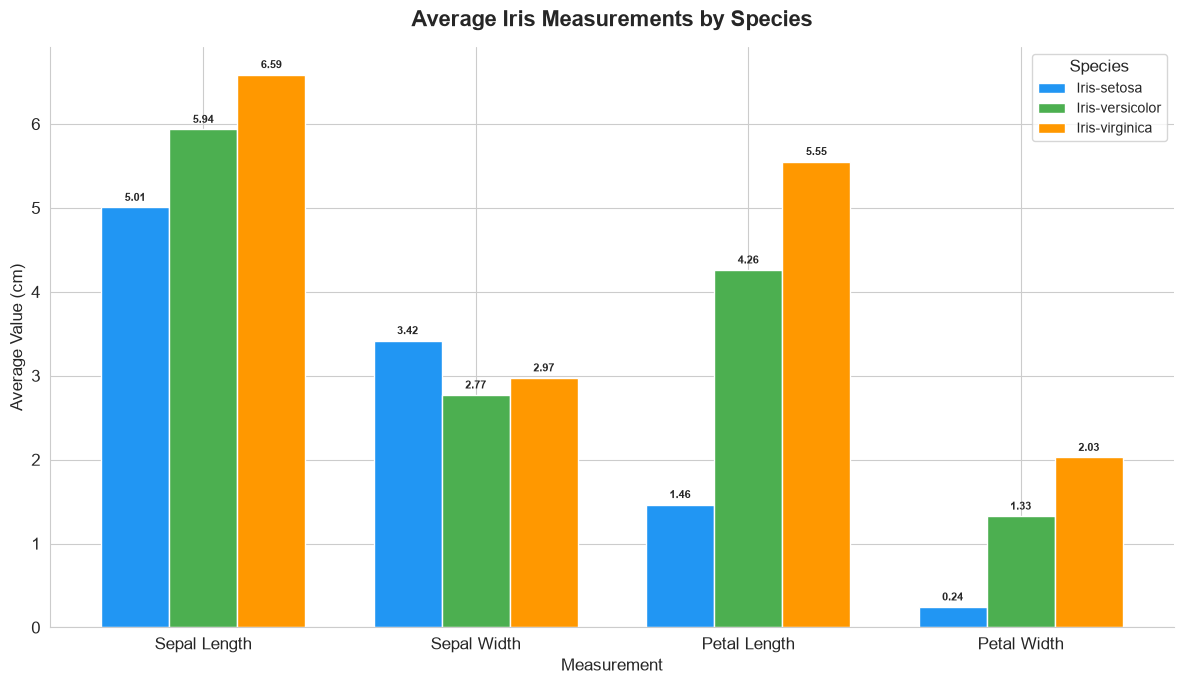

saved outputs\vis2_average_measurements.png


In [8]:
mean_by_species = df.groupby('Species')[numeric_cols].mean()
fig, ax = plt.subplots(figsize=(12, 7))
x = np.arange(len(numeric_cols))
width = 0.25
for i, species in enumerate(mean_by_species.index):
    values = mean_by_species.loc[species].values
    bars = ax.bar(x + i * width, values, width,
                  label=species, color=IRIS_COLORS[species],
                  edgecolor='white', linewidth=1)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.05,
                f'{val:.2f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_title('Average Iris Measurements by Species', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Measurement', fontsize=12)
ax.set_ylabel('Average Value (cm)', fontsize=12)
ax.set_xticks(x + width)
ax.set_xticklabels(['Sepal Length', 'Sepal Width', 'Petal Length', 'Petal Width'])
ax.legend(title='Species', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
_fig = save_figure('vis2_average_measurements.png')
plt.show()
print('saved', _fig)

## 9. Sepal Scatter Plot

Scatter plot of Sepal Length vs Sepal Width, colored by Species.

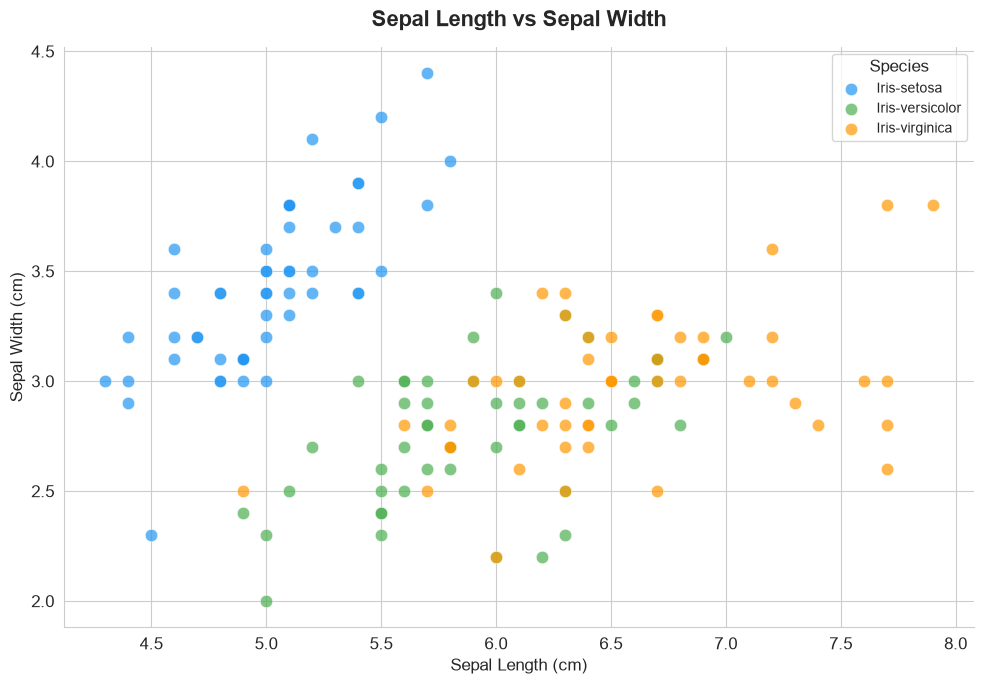

saved outputs\vis3_sepal_scatter.png


In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
for species in df['Species'].unique():
    subset = df[df['Species'] == species]
    ax.scatter(subset['SepalLengthCm'], subset['SepalWidthCm'],
               c=IRIS_COLORS[species], label=species, s=80, alpha=0.7,
               edgecolors='white', linewidth=0.5)
ax.set_title('Sepal Length vs Sepal Width', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Sepal Length (cm)', fontsize=12)
ax.set_ylabel('Sepal Width (cm)', fontsize=12)
ax.legend(title='Species', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
_fig = save_figure('vis3_sepal_scatter.png')
plt.show()
print('saved', _fig)

## 10. Petal Scatter Plot

Scatter plot of Petal Length vs Petal Width, colored by Species.

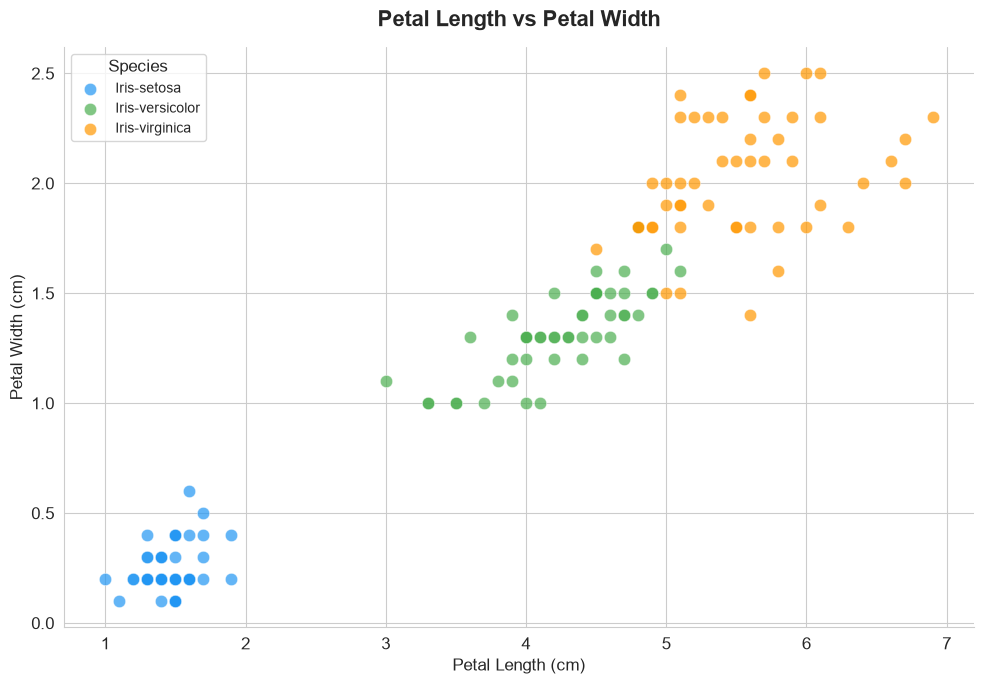

saved outputs\vis4_petal_scatter.png


In [10]:
fig, ax = plt.subplots(figsize=(10, 7))
for species in df['Species'].unique():
    subset = df[df['Species'] == species]
    ax.scatter(subset['PetalLengthCm'], subset['PetalWidthCm'],
               c=IRIS_COLORS[species], label=species, s=80, alpha=0.7,
               edgecolors='white', linewidth=0.5)
ax.set_title('Petal Length vs Petal Width', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Petal Length (cm)', fontsize=12)
ax.set_ylabel('Petal Width (cm)', fontsize=12)
ax.legend(title='Species', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
_fig = save_figure('vis4_petal_scatter.png')
plt.show()
print('saved', _fig)

## 11. Boxplots

Boxplots showing the distribution of each measurement by species.

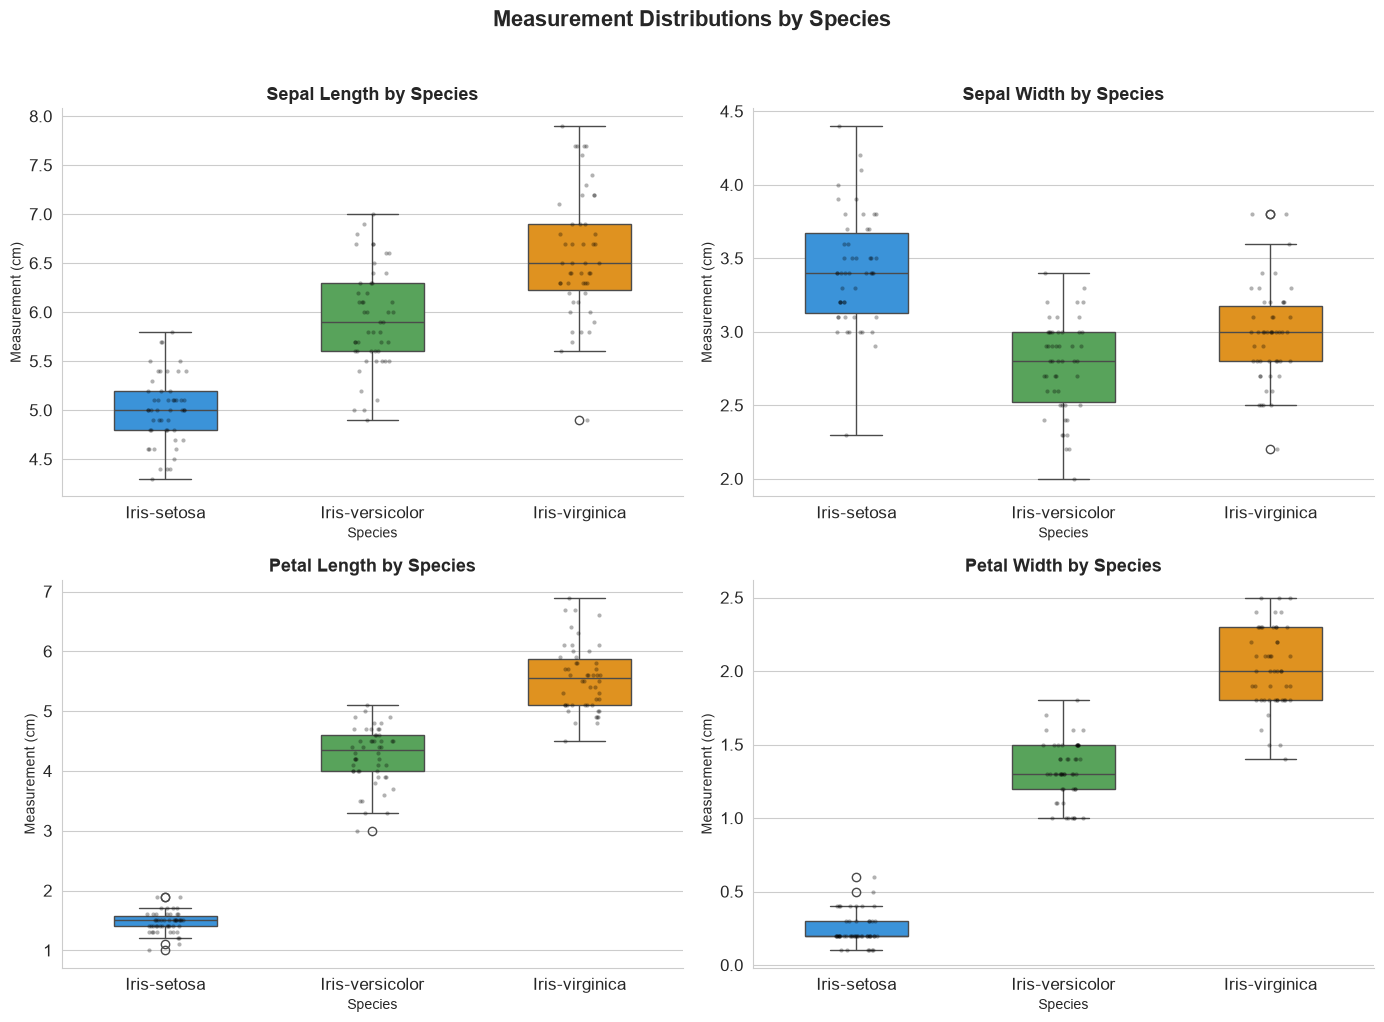

saved outputs\vis5_boxplots.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
measurements = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
titles = ['Sepal Length by Species', 'Sepal Width by Species',
          'Petal Length by Species', 'Petal Width by Species']
for idx, (col, title) in enumerate(zip(measurements, titles)):
    ax = axes[idx // 2][idx % 2]
    bp = sns.boxplot(data=df, x='Species', y=col, ax=ax,
                     palette=IRIS_COLORS, width=0.5)
    bp = sns.stripplot(data=df, x='Species', y=col, ax=ax,
                       color='black', alpha=0.3, size=3)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Species', fontsize=10)
    ax.set_ylabel('Measurement (cm)', fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.suptitle('Measurement Distributions by Species', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
_fig = save_figure('vis5_boxplots.png')
plt.show()
print('saved', _fig)

## 12. Correlation Heatmap

Heatmap showing correlations between numerical features.

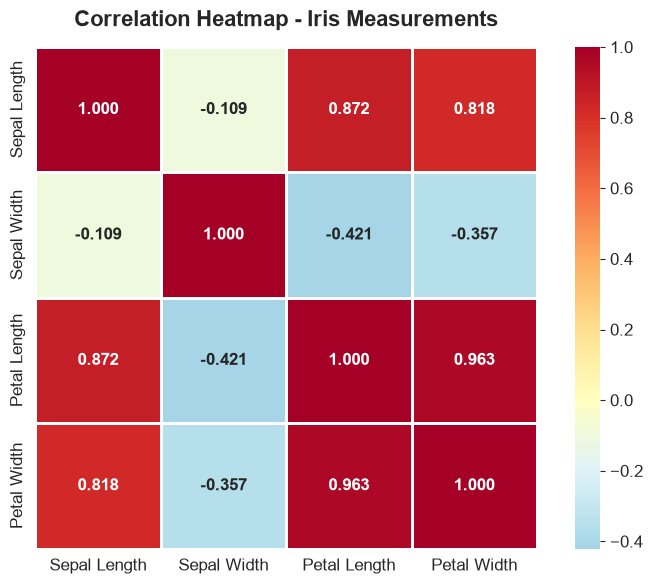

saved outputs\vis6_correlation_heatmap.png


In [12]:
corr = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdYlBu_r',
            center=0, square=True, linewidths=2, ax=ax,
            annot_kws={'size': 12, 'fontweight': 'bold'},
            xticklabels=['Sepal Length', 'Sepal Width', 'Petal Length', 'Petal Width'],
            yticklabels=['Sepal Length', 'Sepal Width', 'Petal Length', 'Petal Width'])
ax.set_title('Correlation Heatmap - Iris Measurements', fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
_fig = save_figure('vis6_correlation_heatmap.png')
plt.show()
print('saved', _fig)

## 13. Pair Plot

A pair plot showing all pairwise relationships between features, colored by Species.

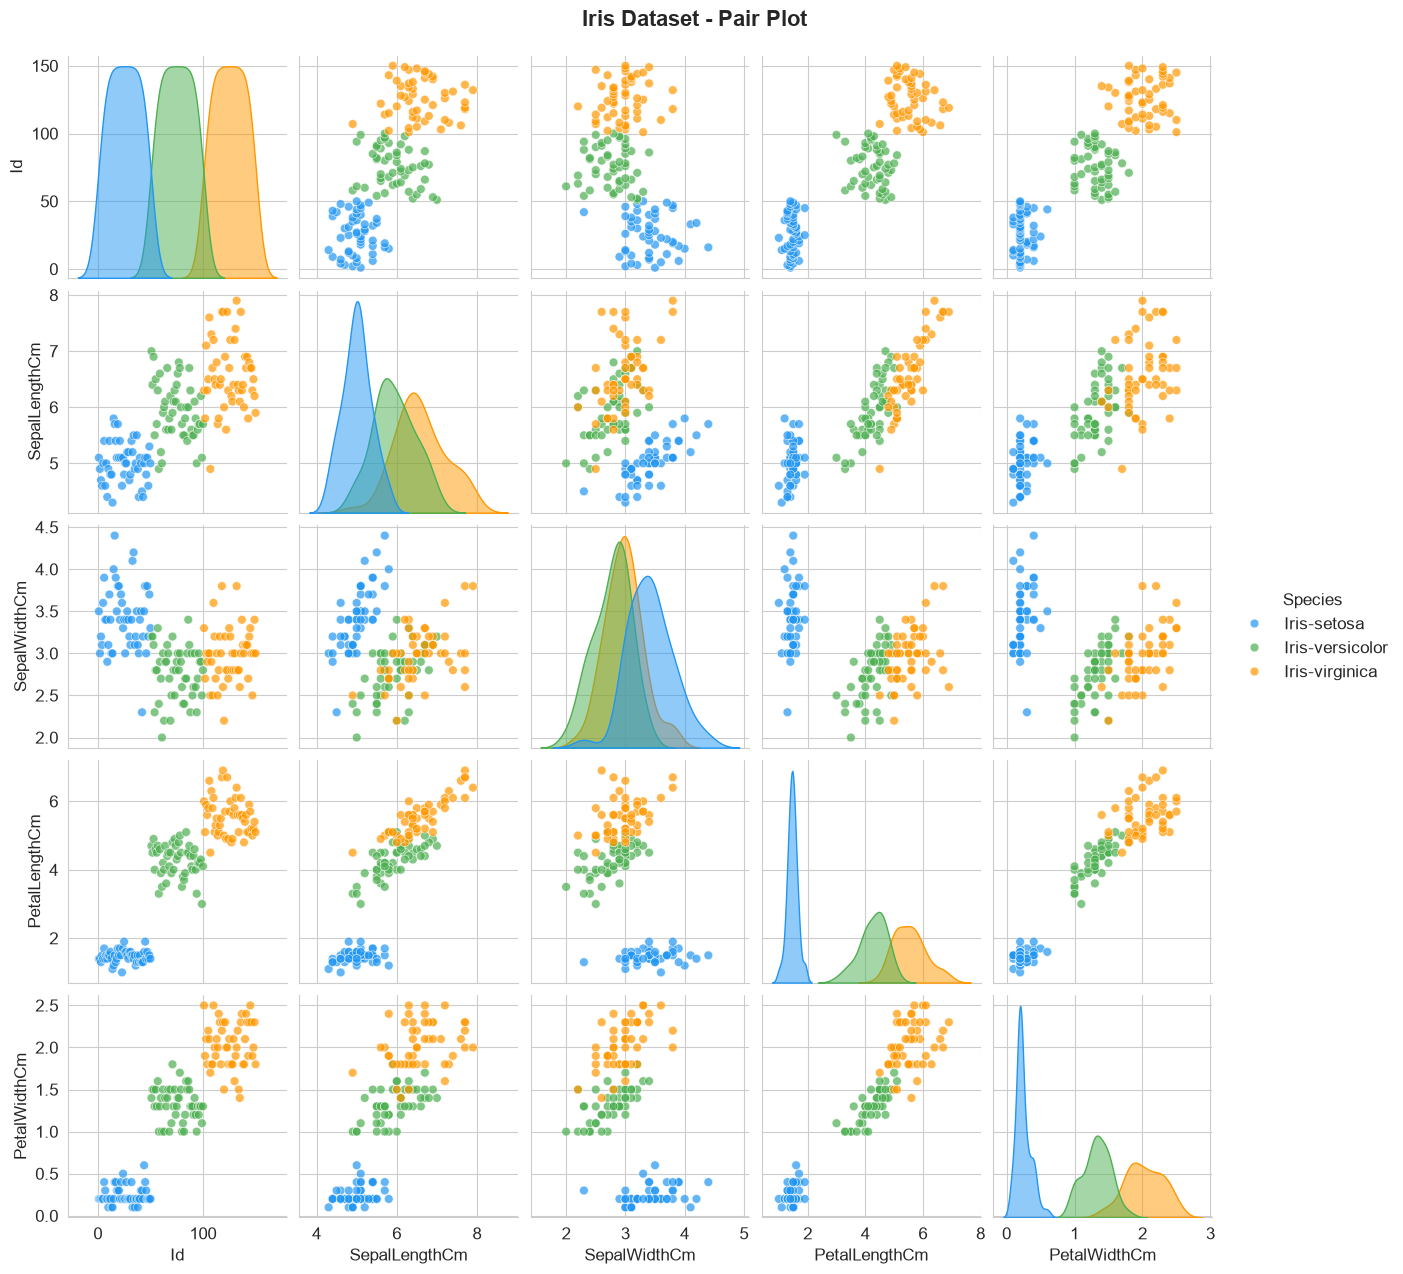

saved outputs\vis7_pairplot.png


In [13]:
pair_plot = sns.pairplot(df, hue='Species', palette=IRIS_COLORS,
                         diag_kind='kde', height=2.5,
                         plot_kws={'alpha': 0.7, 's': 40, 'edgecolor': 'white', 'linewidth': 0.5},
                         diag_kws={'fill': True, 'alpha': 0.5})
pair_plot.figure.suptitle('Iris Dataset - Pair Plot', y=1.02, fontsize=16, fontweight='bold')
_fig = OUT_DIR / 'vis7_pairplot.png'
pair_plot.figure.savefig(_fig, dpi=150, bbox_inches='tight')
plt.show()
print('saved', _fig)

## 14. Final Observations

### Key Findings:

1. **Species Distribution:** All three species have equal representation (50 samples each). The dataset is perfectly balanced.

2. **Sepal Measurements:**
   - Iris-setosa has the shortest sepals (mean: 5.01 cm) but widest sepals (mean: 3.42 cm)
   - Iris-virginica has the longest sepals (mean: 6.59 cm)
   - Sepal measurements show significant overlap between species

3. **Petal Measurements:**
   - Iris-setosa has dramatically smaller petals (mean length: 1.46 cm, width: 0.24 cm)
   - Iris-virginica has the largest petals (mean length: 5.55 cm, width: 2.03 cm)
   - Petal measurements show clear separation between species

4. **Petal Length vs Petal Width:**
   - Strong positive correlation (r = 0.963)
   - Clear linear relationship within and across species
   - Iris-setosa forms a distinct cluster in the lower-left

5. **Best Separating Features:**
   - Petal length and petal width are the best features for distinguishing species
   - Iris-setosa is completely separable from the other two species using petal measurements
   - Iris-versicolor and Iris-virginica show some overlap in sepal measurements but separate well in petal measurements

6. **Key Correlations:**
   - Petal Length and Petal Width: r = 0.963 (very strong positive)
   - Sepal Length and Petal Length: r = 0.872 (strong positive)
   - Sepal Length and Petal Width: r = 0.818 (strong positive)
   - Sepal Width and Petal Length: r = -0.421 (moderate negative)

## 15. Reproducibility

* **Randomness:** none - every chart is a deterministic function of `Iris.csv`.
* **Software:** Python >= 3.9, pandas, NumPy, Matplotlib, Seaborn.
  Exact versions used for this repository are pinned in `requirements.txt`.
* **Saved artefacts:** `outputs/vis1_*.png` ... `outputs/vis7_pairplot.png`
  (on Kaggle they appear under `/kaggle/working/outputs/`).
* **Script equivalent:** `iris_visualization_colab.py` produces the same seven
  figures from the command line.
* **Power BI track:** `powerbi/Iris_Dashboard.pbix`, the DAX measures in
  `PowerBI_DAX.txt`, the theme in `Iris_PowerBI_Theme.json` and the build
  specification in `POWERBI_BUILD_SPEC.md`.

### References

1. Fisher, R.A. (1936). *The use of multiple measurements in taxonomic
   problems.* Annals of Eugenics, 7(2), 179-188.
2. UCI Machine Learning Repository - Iris Data Set.
3. Kaggle - UCI ML Iris Dataset.
